# K-Nearest Neighbors (KNN)

`K` - number of neighbours tp average `(K = 3)`

`X` - features, 2D array
`Y` - target, 1D array

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('Housing.csv')

In [7]:
df['mainroad'] = df['mainroad'].map({'yes': 1, 'no': 0})
df['guestroom'] = df['guestroom'].map({'yes': 1, 'no': 0})
df['basement'] = df['basement'].map({'yes': 1, 'no': 0})
df['hotwaterheating'] = df['hotwaterheating'].map({'yes': 1, 'no': 0})
df['airconditioning'] = df['airconditioning'].map({'yes': 1, 'no': 0})
df['prefarea'] = df['prefarea'].map({'yes': 1, 'no': 0})

df['furnishingstatus'] = df['furnishingstatus'].map({'furnished': 1, 'unfurnished': 0, 'semi-furnished': 1})

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1


In [11]:
y = df['price'] / 1_000_000
X = df.iloc[:, 1:] # all the features without y (price)

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=3))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

In [18]:
print('With scaling:')
print(' MAE:', mean_absolute_error(y_test, y_pred))
print(' R2 score:', r2_score(y_test, y_pred))

With scaling:
 MAE: 1.0477968195718654
 R2 score: 0.5773762005025882


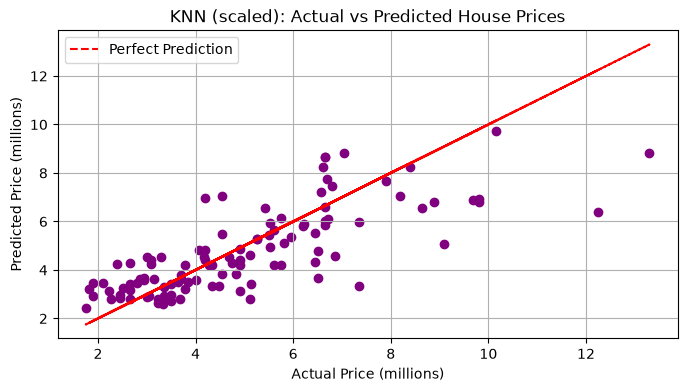

In [22]:
plt.figure(figsize=(8, 4))
plt.scatter(y_test, y_pred, color='purple')
plt.plot(y_test, y_test, color='red', linestyle='--', label='Perfect Prediction')
plt.title('KNN (scaled): Actual vs Predicted House Prices')
plt.xlabel('Actual Price (millions)')
plt.ylabel('Predicted Price (millions)')
plt.legend()
plt.grid(True)


In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__n_neighbors': range(1, 21),
    'model__weights':['uniform', 'distance']
}

grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring='r2')
grid_search.fit(X_train, y_train)

print('Best params:', grid_search.best_params_)
print('Best cross validated R2:', grid_search.best_score_)

Best params: {'model__n_neighbors': 11, 'model__weights': 'distance'}
Best cross validated R2: 0.6315922369503717


In [25]:
best_pred = grid_search.best_estimator_.predict(X_test)
print('Tuned model on the test set')
print(' MAE:', mean_absolute_error(y_test, best_pred))
print(' R2 score:', r2_score(y_test, best_pred))

Tuned model on the test set
 MAE: 1.0238604554009376
 R2 score: 0.5872381961035305


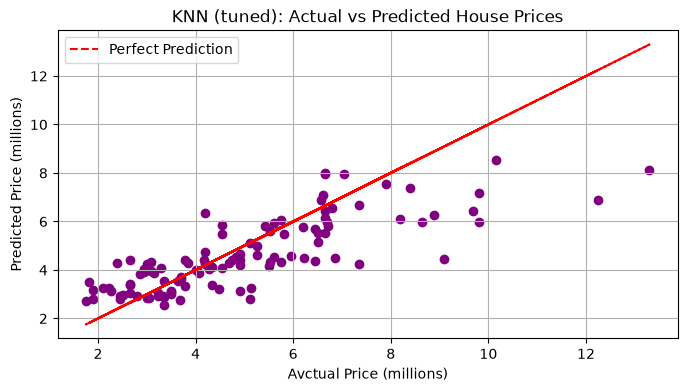

In [29]:
plt.figure(figsize=(8, 4))
plt.scatter(y_test, best_pred, color='purple')
plt.plot(y_test, y_test, color='red', linestyle='--', label='Perfect Prediction')
plt.title('KNN (tuned): Actual vs Predicted House Prices')
plt.xlabel('Avctual Price (millions)')
plt.ylabel('Predicted Price (millions)')
plt.legend()
plt.grid(True)

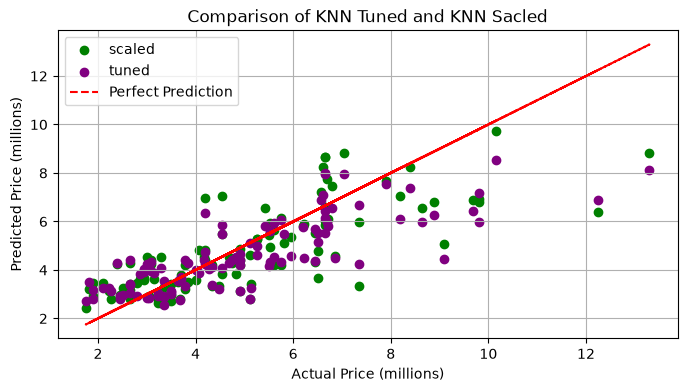

In [34]:
plt.figure(figsize=(8, 4))
plt.scatter(y_test, y_pred, color='green', label='scaled')
plt.scatter(y_test, best_pred, color='purple', label='tuned')
plt.plot(y_test, y_test, color='red', linestyle='--', label='Perfect Prediction')
plt.title('Comparison of KNN Tuned and KNN Sacled')
plt.xlabel('Actual Price (millions)')
plt.ylabel('Predicted Price (millions)')
plt.legend()
plt.grid(True)